In [8]:
# 导入所需的库
import pandas as pd
import numpy as np

#第一问

# 设置 Pandas 显示选项，防止打印时列被折叠或省略
pd.set_option('display.max_columns', None)

# 读取 TSV 文件
# sep='\t' 表示列与列之间是用 Tab 键分隔的
file_name = "earthquakes-2026-10-14_20-30-32_+0800.tsv" 
Sig_Eqs = pd.read_csv(file_name, sep='\t')

#查看文件中所有的行数与列数
print(Sig_Eqs.shape)

(6698, 49)


In [9]:
#需要的列为'Total Deaths'，即总死亡人数
death_col = 'Total Deaths'

# 将字符串转换为数值型 (float)，因为pandas最初读取数据时读成了str即字符串型，这会导致运算错误
# errors='coerce' ,如果遇到无法转换的字符（比如 "approx" 或空字符串），就强制变成 NaN
Sig_Eqs[death_col] = pd.to_numeric(Sig_Eqs[death_col], errors='coerce')

# 处理缺失值
# 转换后，原来的空值变成了 NaN，无法参与加法运算，用 0 将其填充
Sig_Eqs[death_col] = Sig_Eqs[death_col].fillna(0)

# 验证是否转换成功
print(Sig_Eqs[death_col].dtype)

float64


In [11]:
# 按国家（Country）分组，计算每个国家的死亡总人数
# groupby('Country') 把相同国家的行归为一组，[death_col]是要计算的列，sum()对每组求和，生成一个一维数组，country是索引，死亡总人数是值
deaths_by_country = Sig_Eqs.groupby('Country')[death_col].sum()

# 降序排序，并取前 20 名, ascending=False 表示从大到小排,head()意为取前二十行
top20_countries = deaths_by_country.sort_values(ascending=False).head(20)

# 6. 打印结果
print("地震导致死亡人数最多的前 20 个国家 \n", top20_countries)

地震导致死亡人数最多的前 20 个国家 
 Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64


In [14]:
#第二问

import matplotlib.pyplot as plt

# 1数据清洗，将 'Ms' 转换为数值型
# 同样使用 errors='coerce' 处理无法转换的文本或空值,变成NaN
Sig_Eqs['Ms'] = pd.to_numeric(Sig_Eqs['Ms'], errors='coerce')

# 2. 过滤数据，筛选出 Ms > 3.0 的地震，包含了 NaN 的行会被自动排除， NaN > 3.0 结果为 False
strong_eqs = Sig_Eqs[Sig_Eqs['Ms'] > 3.0]

# 3. 按年份统计全球地震次数
# groupby('Year') 后使用 size() 统计每年的行数，即地震次数，这里生成一个一维数组，Year为索引列，次数统计为值
earthquakes_per_year = strong_eqs.groupby('Year').size()

print(earthquakes_per_year)

Year
-2000.0    1
-479.0     1
-426.0     1
-400.0     1
-373.0     1
          ..
 2015.0    1
 2017.0    1
 2019.0    1
 2024.0    1
 2025.0    3
Length: 511, dtype: int64


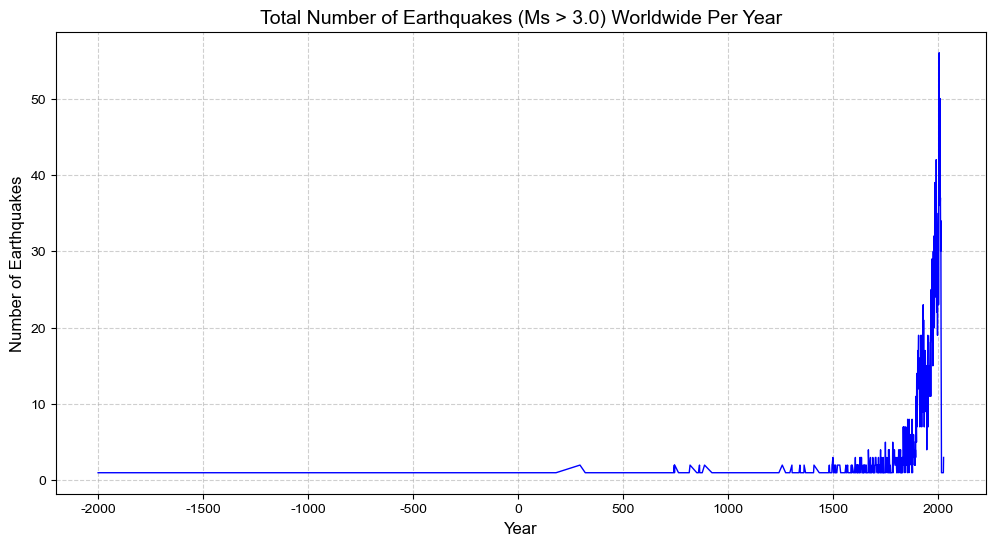

In [18]:
# 绘制时间序列图
plt.figure(figsize=(12, 6)) # 设置画布大小
##index即为年份，values就是地震次数，先后定义横纵坐标
plt.plot(earthquakes_per_year.index, earthquakes_per_year.values, color='blue', linewidth=1)

# 设置图表标题和坐标轴标签
plt.title('Total Number of Earthquakes (Ms > 3.0) Worldwide Per Year', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Earthquakes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) # 添加网格线

# 显示图表
plt.show()

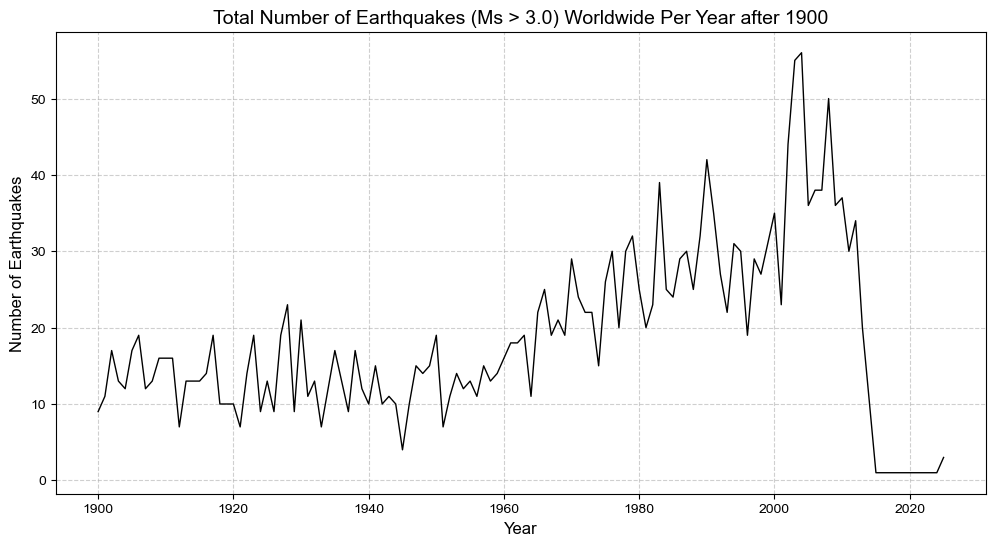

In [20]:
# 只筛选 1900 年之后的数据来画图
recent_eqs = earthquakes_per_year[earthquakes_per_year.index >= 1900]
plt.figure(figsize=(12, 6)) # 设置画布大小
plt.plot(recent_eqs.index, recent_eqs.values,color='black', linewidth=1)

# 设置图表标题和坐标轴标签
plt.title('Total Number of Earthquakes (Ms > 3.0) Worldwide Per Year after 1900', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Earthquakes', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) # 添加网格线

# 显示图表
plt.show()

In [5]:
#第三问
import pandas as pd
import numpy as np

file_name = "earthquakes-2026-10-14_20-30-32_+0800.tsv" 
Sig_Eqs = pd.read_csv(file_name, sep='\t')

import pandas as pd

# 确保代表震级的 Mag 是数值型
Sig_Eqs['Mag'] = pd.to_numeric(Sig_Eqs['Mag'], errors='coerce')

# 定义函数
def CountEq_LargestEq(country):
    # 筛选国家，使用布尔索引，将返回为true的行存入一个dataframe
    df = Sig_Eqs[Sig_Eqs['Country'] == country] 
    
    # 用 len() 获取新建的dataframe的行数
    count = len(df)

    if df['Mag'].count() == 0: #多一条判断，若有的国家Mag记录为空，会报错，日期地点设置为Unknown
        return count, "Unknown", "Unknown"
    
    # 找 Mag 最大的那一行
    max_eq = df.loc[df['Mag'].idxmax()] #idmax()方法为获取最大值所在的行数，即最大值所在的索引，loc()即利用索引值定位
    
    # 定义年月日，Year为年份，Mo为月份，Dy为天，取最大值对应的那一行的日期列对应的值
        # 判断月和日是否为 NaN (空值)，如果是就显示为 "Unknown"，否则取整
    y = int(max_eq['Year'])
    m = int(max_eq['Mo']) if pd.notna(max_eq['Mo']) else "error"  #notna是检查是否为空的方法
    d = int(max_eq['Dy']) if pd.notna(max_eq['Dy']) else "error"
    
    # 组装日期
    date = f"{y}-{m}-{d}" #格式化字符串，短横线格式
    location = max_eq['Location Name']
    
    return count, date, location

# 遍历所有国家
results = []
for country in Sig_Eqs['Country'].dropna().unique():  #.dropna()为去掉列中空值的方法，unique()为去重的方法，每个国家之统计一次
    count, date, location = CountEq_LargestEq(country)  #函数返回的三个变量被新定义的三个变量接收
    results.append([country, count, date, location]) #构建一个二维列表

# 转换为 DataFrame，按次数降序排列
results_df = pd.DataFrame(results, columns=['Country', 'Total Earthquakes', 'Largest EQ Date', 'Largest EQ Location'])  #创造表头
results_df = results_df.sort_values(by='Total Earthquakes', ascending=False).reset_index(drop=True) #按照总的地震数降序排列，reset.index()为重置索引

# 打印结果
print(results_df.to_string(index=False))

                                     Country  Total Earthquakes   Largest EQ Date                                  Largest EQ Location
                                       CHINA                626         1668-7-25                            CHINA:  SHANDONG PROVINCE
                                       JAPAN                429         2011-3-11                                       JAPAN:  HONSHU
                                   INDONESIA                427        2004-12-26          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
                                        IRAN                385         856-12-22                                IRAN:  DAMGHAN, QUMIS
                                      TURKEY                359        1939-12-26                                    TURKEY:  ERZINCAN
                                       ITALY                338         1915-1-13                   ITALY:  MARSICA, AVEZZANO, ABRUZZI
                                      GREECE           